## Day 15 Naive Attention

In [12]:
!apt install -y nsight-compute-2026.3.1

import os
os.environ["PATH"] += ":/opt/nvidia/nsight-compute/2026.3.1"

!ncu --version

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
nsight-compute-2026.3.1 is already the newest version (2026.3.1.2-1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
NVIDIA (R) Nsight Compute Command Line Profiler
Copyright (c) 2018-2026 NVIDIA Corporation
Version 2026.3.1.0 (build 38829034) (public-release)


In [13]:
%%writefile attn_kernels.py
import torch, triton, triton.language as tl

DEVICE = triton.runtime.driver.active.get_active_torch_device()

@triton.jit
def attn_row_kernel(Q, K, V, O, N, sm_scale, D: tl.constexpr, BLOCK_N: tl.constexpr):
    row = tl.program_id(0)
    head = tl.program_id(1)
    base = head * N * D

    offs_d = tl.arange(0, D)
    offs_n = tl.arange(0, BLOCK_N)
    mask_n = offs_n < N

    q = tl.load(Q + base + row * D + offs_d).to(tl.float32)
    k = tl.load(K + base + offs_n[:, None] * D + offs_d[None, :], mask=mask_n[:, None], other=0.0).to(tl.float32)

    s = tl.sum(k * q[None, :], axis=1) * sm_scale
    s = tl.where(mask_n, s, float('-inf'))

    p = tl.exp(s - tl.max(s, axis=0))
    p = p / tl.sum(p, axis=0)

    v = tl.load(V + base + offs_n[:, None] * D + offs_d[None, :], mask=mask_n[:, None], other=0.0).to(tl.float32)
    o = tl.sum(p[:, None] * v, axis=0)

    tl.store(O + base + row * D + offs_d, o.to(O.dtype.element_ty))

def attention_triton(q, k, v):
    BH, N, D = q.shape

    o = torch.empty_like(q)
    attn_row_kernel[(N, BH)](q, k, v, o, N, D ** -0.5, D=D, BLOCK_N=triton.next_power_of_2(N))

    return o

def attention_ref(q, k, v):
    s = (q @ k.transpose(-1, -2)) * (q.shape[-1] ** -0.5)

    return torch.softmax(s, dim=-1) @ v

Overwriting attn_kernels.py


In [14]:
import torch, triton
import torch.nn.functional as F
from attn_kernels import attention_triton, attention_ref, DEVICE

BH, D = 16, 64

In [15]:
for N in [16, 100, 130, 256]:
    q, k, v = (torch.randn(BH, N, D, device=DEVICE) for _ in range(3))
    assert torch.allclose(attention_triton(q, k, v), attention_ref(q, k, v), atol=1e-4), N

print("all match")

all match


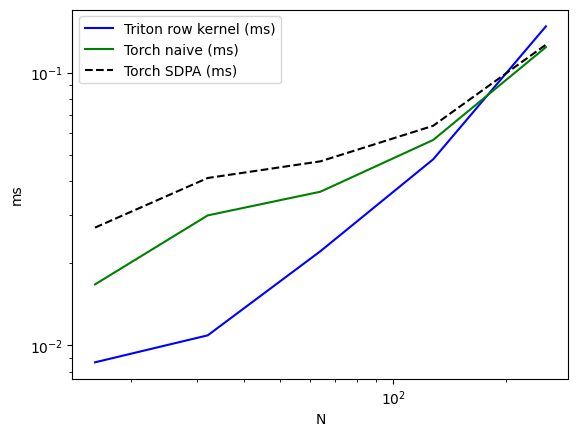

attention-naive-latency:
       N  Triton row kernel (ms)  Torch naive (ms)  Torch SDPA (ms)
0   16.0                0.008675          0.016739         0.027028
1   32.0                0.010891          0.029958         0.041073
2   64.0                0.022152          0.036590         0.047267
3  128.0                0.048084          0.056614         0.063806
4  256.0                0.147646          0.123827         0.126468


In [16]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['N'],
        x_vals=[2**i for i in range(4, 9)],
        x_log=True,
        y_log=True,
        line_arg='provider',
        line_vals=['triton', 'naive', 'sdpa'],
        line_names=['Triton row kernel', 'Torch naive', 'Torch SDPA'],
        styles=[('blue', '-'), ('green', '-'), ('black', '--')],
        ylabel='ms',
        plot_name='attention-naive-latency',
        args={},
    )
)

def bench(N, provider):
    q, k, v = (torch.randn(BH, N, D, device=DEVICE) for _ in range(3))
    fns = {
        'triton': lambda: attention_triton(q, k, v),
        'naive':  lambda: attention_ref(q, k, v),
        'sdpa':   lambda: F.scaled_dot_product_attention(q, k, v),
    }
    return triton.testing.do_bench(fns[provider])

bench.run(print_data=True, show_plots=True)

In [17]:
def peak_mb(fn):
    torch.cuda.empty_cache(); torch.cuda.synchronize()

    base = torch.cuda.memory_allocated()

    torch.cuda.reset_peak_memory_stats()

    fn(); torch.cuda.synchronize()

    return (torch.cuda.max_memory_allocated() - base) / 2**20

for N in [512, 1024, 2048, 4096]:

    q, k, v = (torch.randn(BH, N, D, device=DEVICE) for _ in range(3))
    mb = peak_mb(lambda: attention_ref(q, k, v))
    score_mb = BH * N * N * 4 / 2**20

    print(f"N={N:5d}  peak={mb:8.0f}MB | one score matrix={score_mb:8.0f} MB")

N=  512  peak=      34MB | one score matrix=      16 MB
N= 1024  peak=     132MB | one score matrix=      64 MB
N= 2048  peak=     520MB | one score matrix=     256 MB
N= 4096  peak=    2064MB | one score matrix=    1024 MB


In [18]:
%%writefile attn_prof.py
import sys, torch
import torch.nn.functional as F
from attn_kernels import attention_triton, attention_ref, DEVICE

torch.backends.cuda.matmul.allow_tf32 = False

impl, N = sys.argv[1], int(sys.argv[2])

BH, D = 16, 64
q, k, v = (torch.randn(BH, N, D, device=DEVICE) for _ in range(3))

fn = {'triton': lambda: attention_triton(q, k, v),
      'naive':  lambda: attention_ref(q, k, v),
      'sdpa':   lambda: F.scaled_dot_product_attention(q, k, v)
}[impl]

fn(); torch.cuda.synchronize()
torch.cuda.cudart().cudaProfilerStart()
fn(); torch.cuda.synchronize()
torch.cuda.cudart().cudaProfilerStop()

Overwriting attn_prof.py


In [22]:
import subprocess, io, pandas as pd

METRICS = ",".join([
    "dram__bytes_read.sum", "dram__bytes_write.sum", "lts__t_bytes.sum",
    "smsp__sass_thread_inst_executed_op_fadd_pred_on.sum",
    "smsp__sass_thread_inst_executed_op_fmul_pred_on.sum",
    "smsp__sass_thread_inst_executed_op_ffma_pred_on.sum",
    "gpu__time_duration.sum",
])

TIME_UNIT = {
    "nsecond": 1e-9, "ns": 1e-9,
    "usecond": 1e-6, "us": 1e-6,
    "msecond": 1e-3, "ms": 1e-3,
    "second": 1, "s": 1
}

def profile(impl, N, extra=()):
    log = f"/tmp/{impl}_{N}.csv"
    subprocess.run(["ncu",
                    "--profile-from-start", "off", "--csv", "--page", "raw",
                    "--print-units", "base", "--log-file", log,
                    "--metrics", METRICS, *extra,
                    "python", "attn_prof.py", impl, str(N)], check=True)

    lines = [l for l in open(log) if l.startswith('"')]

    raw = pd.read_csv(io.StringIO("".join(lines)), thousands=",")
    units, df = raw.iloc[0], raw.iloc[1:]

    # Explicitly replace commas before converting to float
    m = lambda c: df[c].astype(str).str.replace(",", "").astype(float).sum()

    flops = (m("smsp__sass_thread_inst_executed_op_fadd_pred_on.sum")
             + m("smsp__sass_thread_inst_executed_op_fmul_pred_on.sum")
             + 2 * m("smsp__sass_thread_inst_executed_op_ffma_pred_on.sum"))

    dram = m("dram__bytes_read.sum") + m("dram__bytes_write.sum")
    l2 = m("lts__t_bytes.sum")
    time_s = m("gpu__time_duration.sum") * TIME_UNIT[units["gpu__time_duration.sum"]]

    return dict(impl=impl, N=N, kernels=len(df),
                gflop=flops / 1e9, analytic_gflop=4 * BH * N * N * D / 1e9,
                dram_MB=dram / 1e6, l2_MB=l2 / 1e6,
                AI_dram=flops / dram, AI_l2=flops / l2,
                time_s=time_s)

rows = []
for impl, Ns in [('triton', [64, 128, 256]),
                 ('naive',  [64, 256, 1024, 4096]),
                 ('sdpa',   [64, 256, 1024, 4096])]:
    for N in Ns:
        rows.append(profile(impl, N))

results = pd.DataFrame(rows)
results.round(3)

,impl,N,kernels,gflop,analytic_gflop,dram_MB,l2_MB,AI_dram,AI_l2,time_s
0,triton,64,1,0.026,0.017,0.890,15.827,29.156,1.640,0.000
1,triton,128,1,0.102,0.067,1.804,52.133,56.675,1.961,0.000
2,triton,256,1,0.406,0.268,3.612,147.823,112.350,2.745,0.000
3,naive,64,4,0.069,0.017,1.820,3.047,38.089,22.743,0.000
4,naive,256,4,0.429,0.268,18.394,33.095,23.323,12.962,0.000
5,naive,1024,4,6.850,4.295,382.272,507.164,17.919,13.506,0.002
6,naive,4096,4,112.829,68.719,7435.607,8071.102,15.174,13.979,0.028
7,sdpa,64,9,0.069,0.017,2.861,4.992,24.249,13.896,0.000
8,sdpa,256,9,0.428,0.268,26.806,44.220,15.984,9.690,0.000
9,sdpa,1024,9,6.835,4.295,498.444,626.343,13.713,10.913,0.002


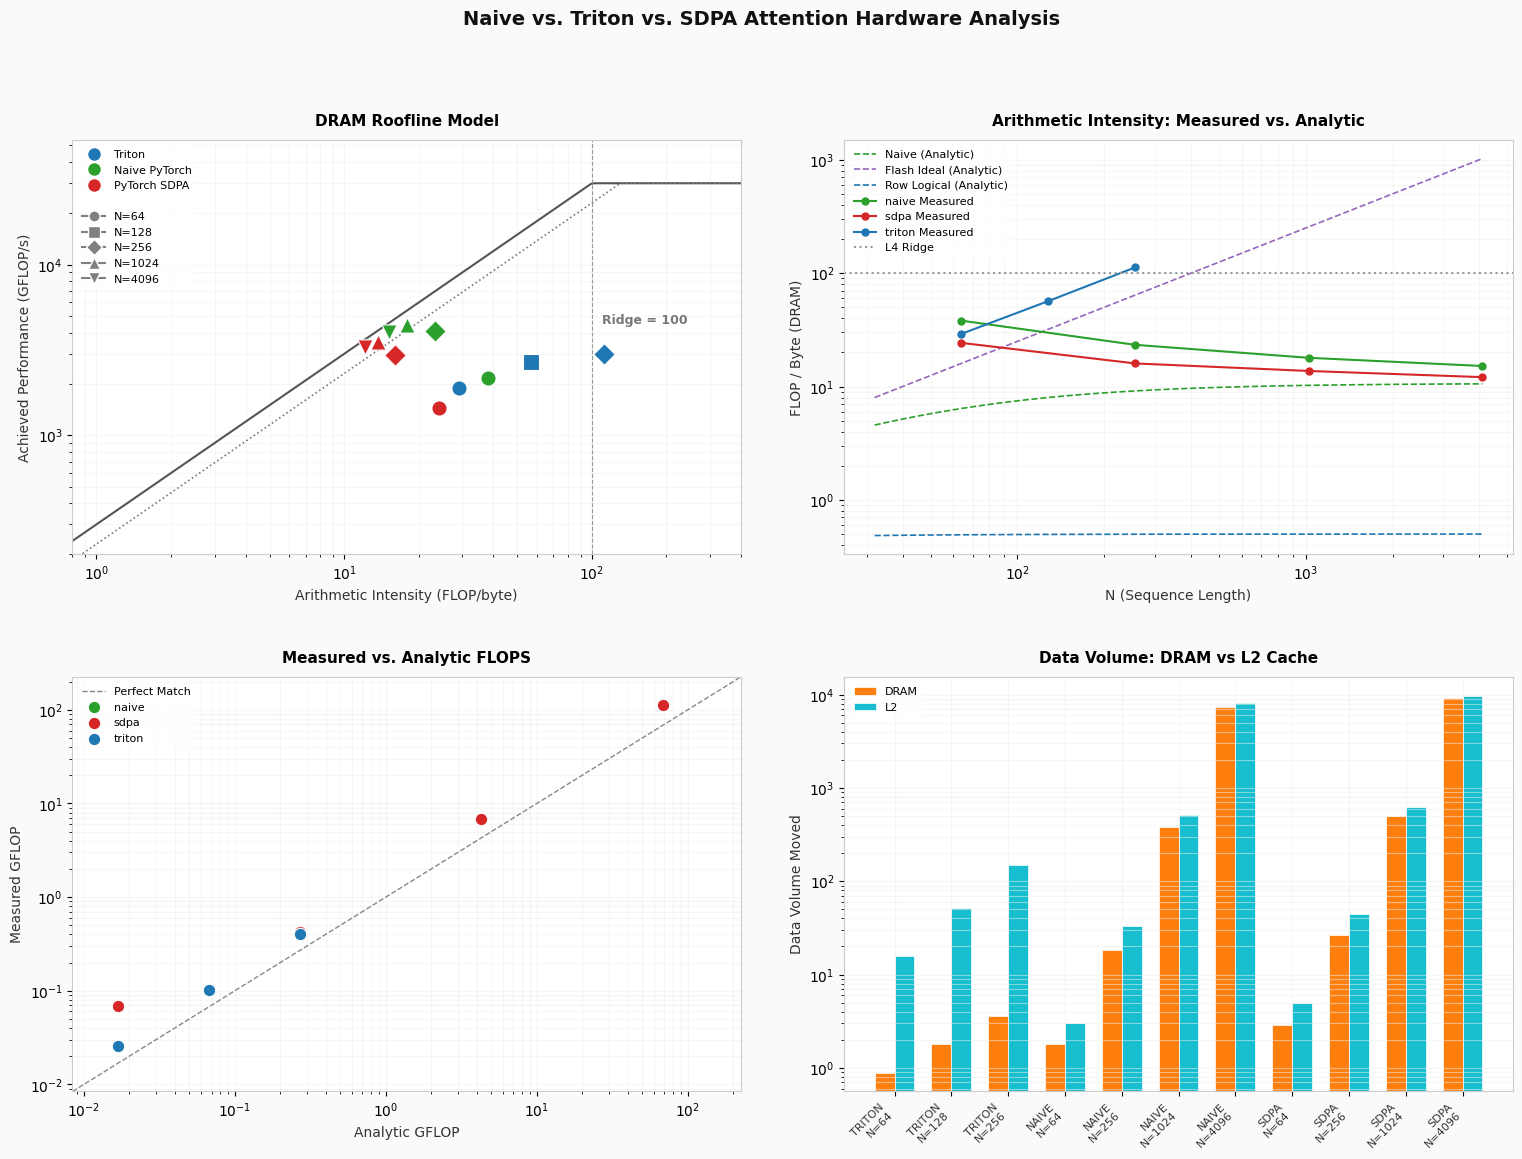

In [28]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#EEEEEE'
plt.rcParams['grid.alpha'] = 0.5

PEAK, BW, BW_MEAS = 30_000, 300, 230
RIDGE = PEAK / BW
COL = {'triton': '#1F77B4', 'naive': '#2CA02C', 'sdpa': '#D62728'}
MARKERS = {64: 'o', 128: 's', 256: 'D', 1024: '^', 4096: 'v'}

df = results.copy()
df = df[df.time_s > 1e-6]
df['gflops_s'] = df.gflop / df.time_s

fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor='#FAFAFA')

ax = axes[0, 0]
ax.set_facecolor('#FFFFFF')
ai = np.logspace(-1, 3, 300)

ax.plot(ai, np.minimum(PEAK, ai * BW), '-', color='#555555', lw=1.5, label='L4 Theoretical Roof')
ax.plot(ai, np.minimum(PEAK, ai * BW_MEAS), ':', color='#777777', lw=1.2, label='L4 Measured Roof')
ax.axvline(RIDGE, color='#999999', ls='--', lw=0.8)
ax.text(RIDGE * 1.1, PEAK * 0.15, f'Ridge = {RIDGE:.0f}', color='#777777', fontsize=9, fontweight='bold')

for impl, g in df.groupby('impl'):
    for N_val, row in g.groupby('N'):
        ax.scatter(row.AI_dram, row.gflops_s, c=COL[impl], marker=MARKERS[N_val],
                   s=120, edgecolors='white', linewidths=0.8, zorder=5)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='none', marker='o', markerfacecolor=COL['triton'], markeredgecolor='white', markersize=10, label='Triton'),
    Line2D([0], [0], color='none', marker='o', markerfacecolor=COL['naive'], markeredgecolor='white', markersize=10, label='Naive PyTorch'),
    Line2D([0], [0], color='none', marker='o', markerfacecolor=COL['sdpa'], markeredgecolor='white', markersize=10, label='PyTorch SDPA'),
    Line2D([0], [0], color='none', label=''),
    Line2D([0], [0], color='gray', marker=MARKERS[64], markerfacecolor='gray', markeredgecolor='white', markersize=8, label='N=64'),
    Line2D([0], [0], color='gray', marker=MARKERS[128], markerfacecolor='gray', markeredgecolor='white', markersize=8, label='N=128'),
    Line2D([0], [0], color='gray', marker=MARKERS[256], markerfacecolor='gray', markeredgecolor='white', markersize=8, label='N=256'),
    Line2D([0], [0], color='gray', marker=MARKERS[1024], markerfacecolor='gray', markeredgecolor='white', markersize=8, label='N=1024'),
    Line2D([0], [0], color='gray', marker=MARKERS[4096], markerfacecolor='gray', markeredgecolor='white', markersize=8, label='N=4096'),
]

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.8, 400)
ax.set_ylim(200, PEAK * 1.8)
ax.set_xlabel('Arithmetic Intensity (FLOP/byte)', fontsize=10, color='#333333')
ax.set_ylabel('Achieved Performance (GFLOP/s)', fontsize=10, color='#333333')
ax.set_title('DRAM Roofline Model', fontsize=11, fontweight='bold', pad=10)
ax.legend(handles=legend_elements, fontsize=8, loc='upper left', frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="-")

ax = axes[0, 1]
ax.set_facecolor('#FFFFFF')
Ns = np.logspace(5, 12, 60, base=2)

analytic = {
    'Naive (Analytic)':       (lambda n: 4*n*n*D / (4*(4*n*D + 6*n*n)), '#2CA02C'),
    'Flash Ideal (Analytic)': (lambda n: 4*n*n*D / (4*4*n*D),          '#9467BD'),
    'Row Logical (Analytic)': (lambda n: 4*n*n*D / (4*n*(2*n*D + 2*D)), '#1F77B4'),
}

for name, (f, c) in analytic.items():
    ax.plot(Ns, f(Ns), ls='--', color=c, lw=1.2, label=name)

for impl, g in df.groupby('impl'):
    ax.plot(g.N, g.AI_dram, 'o-', color=COL[impl], lw=1.5, markersize=5, label=f'{impl} Measured')

ax.axhline(RIDGE, color='#999999', ls=':', label='L4 Ridge')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('N (Sequence Length)', fontsize=10, color='#333333')
ax.set_ylabel('FLOP / Byte (DRAM)', fontsize=10, color='#333333')
ax.set_title('Arithmetic Intensity: Measured vs. Analytic', fontsize=11, fontweight='bold', pad=10)
ax.legend(fontsize=8, frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="-")

ax = axes[1, 0]
ax.set_facecolor('#FFFFFF')
lim = [df[['gflop', 'analytic_gflop']].min().min() * 0.5,
       df[['gflop', 'analytic_gflop']].max().max() * 2]

ax.plot(lim, lim, '--', color='#888888', lw=1, label='Perfect Match')

for impl, g in df.groupby('impl'):
    ax.scatter(g.analytic_gflop, g.gflop, c=COL[impl], s=80, edgecolors='white', linewidths=0.8, zorder=5, label=impl)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel('Analytic GFLOP', fontsize=10, color='#333333')
ax.set_ylabel('Measured GFLOP', fontsize=10, color='#333333')
ax.set_title('Measured vs. Analytic FLOPS', fontsize=11, fontweight='bold', pad=10)
ax.legend(fontsize=8, frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="-")

ax = axes[1, 1]
ax.set_facecolor('#FFFFFF')

index = np.arange(len(df))
bar_width = 0.35

ax.bar(index - bar_width/2, df.dram_MB, bar_width, label='DRAM', color='#FF7F0E', edgecolor='white', linewidth=0.5)
ax.bar(index + bar_width/2, df.l2_MB, bar_width, label='L2', color='#17BECF', edgecolor='white', linewidth=0.5)

labels = [f'{r.impl.upper()}\nN={int(r.N)}' for _, r in df.iterrows()]

ax.set_xticks(index)
ax.set_xticklabels(labels, fontsize=8, rotation=45, ha='right', color='#333333')

ax.set_yscale('log')
ax.set_ylabel('Data Volume Moved', fontsize=10, color='#333333')
ax.set_title('Data Volume: DRAM vs L2 Cache', fontsize=11, fontweight='bold', pad=10)

ax.legend(fontsize=8, frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="-")

fig.suptitle('Naive vs. Triton vs. SDPA Attention Hardware Analysis', fontsize=14, fontweight='bold', color='#111111', y=0.99)
fig.tight_layout(pad=3.5)
plt.savefig('attention_ncu.png', dpi=250, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()